# 04. Exploratory Data Analysis (Training Set Only)

**Project:** Explainable ML for screening kidney abnormality markers among US adults with diabetes (NHANES 2017–March 2020 pre-pandemic)

## Objective
Describe the distributions, missingness, outliers, and outcome patterns of candidate predictors in order to justify preprocessing and feature-selection decisions.

## Data and scope

- **Input:** `data/processed/train.csv` (n = 1,204; 80% stratified split, random_state=42).
- **Outcome:** `kidney_marker` = 1 if eGFR < 60 mL/min/1.73 m² OR UACR ≥ 30 mg/g; 0 if both are measured and normal.
- **Design:** Cross-sectional. Findings represent associations at a single time point, not causation or future risk.
- **Leakage safeguard:** The test set (n = 302) is not opened in this notebook.
- **Not survey-weighted:** Statistics are unweighted sample statistics and do not estimate US population prevalence.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/processed/train.csv")

print("Training dataset shape:", train.shape)
print("\nKidney marker distribution:")
print(train["kidney_marker"].value_counts())

Training dataset shape: (1204, 35)

Kidney marker distribution:
kidney_marker
0.0    684
1.0    520
Name: count, dtype: int64


## 1. Descriptive statistics and skewness

**Purpose:** Summarise each continuous candidate predictor (count, mean, SD, range) and quantify skewness to decide whether transformation is needed.

**Method:** `describe()` and sample skewness. As a rule of thumb, |skew| > 1 indicates a pronounced tail.

**Variables:** age (`RIDAGEYR`), family income-to-poverty ratio (`INDFMPIR`), HbA1c (`LBXGH`), BMI (`BMXBMI`), waist circumference (`BMXWAIST`), systolic and diastolic blood pressure (`BPXOSY1`, `BPXODI1`).

In [2]:
# Continuous candidate predictors
num = [
    "RIDAGEYR",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BMXWAIST",
    "BPXOSY1",
    "BPXODI1"
]

# Descriptive statistics
print("Descriptive statistics:")
print(train[num].describe().round(2).T)

# Skewness
print("\nSkewness:")
print(train[num].skew().round(2))

Descriptive statistics:
           count    mean    std   min     25%     50%     75%    max
RIDAGEYR  1204.0   61.95  12.71  20.0   54.00   63.00   71.00   80.0
INDFMPIR  1041.0    2.48   1.58   0.0    1.15    1.96    3.94    5.0
LBXGH     1187.0    7.45   1.64   4.1    6.50    6.90    8.10   16.2
BMXBMI    1178.0   32.88   7.83  15.4   27.60   31.55   36.50   84.4
BMXWAIST  1129.0  110.23  15.97  67.4   99.00  109.10  120.10  170.8
BPXOSY1   1078.0  131.70  21.18  66.0  117.00  129.00  144.00  224.0
BPXODI1   1078.0   75.26  12.19  36.0   67.00   75.00   83.00  137.0

Skewness:
RIDAGEYR   -0.54
INDFMPIR    0.43
LBXGH       1.60
BMXBMI      1.39
BMXWAIST    0.41
BPXOSY1     0.68
BPXODI1     0.22
dtype: float64


## 2. Distributions by outcome status

**Purpose:** Visually compare each predictor's distribution between participants with and without a kidney marker, and screen for implausible values and coding artefacts.

**Method:** Overlaid histograms (30 bins) by `kidney_marker`. Missing values are omitted from each panel.

**What to look for:** distribution shift between groups, pile-ups at a single value (top-coding), and impossible values.

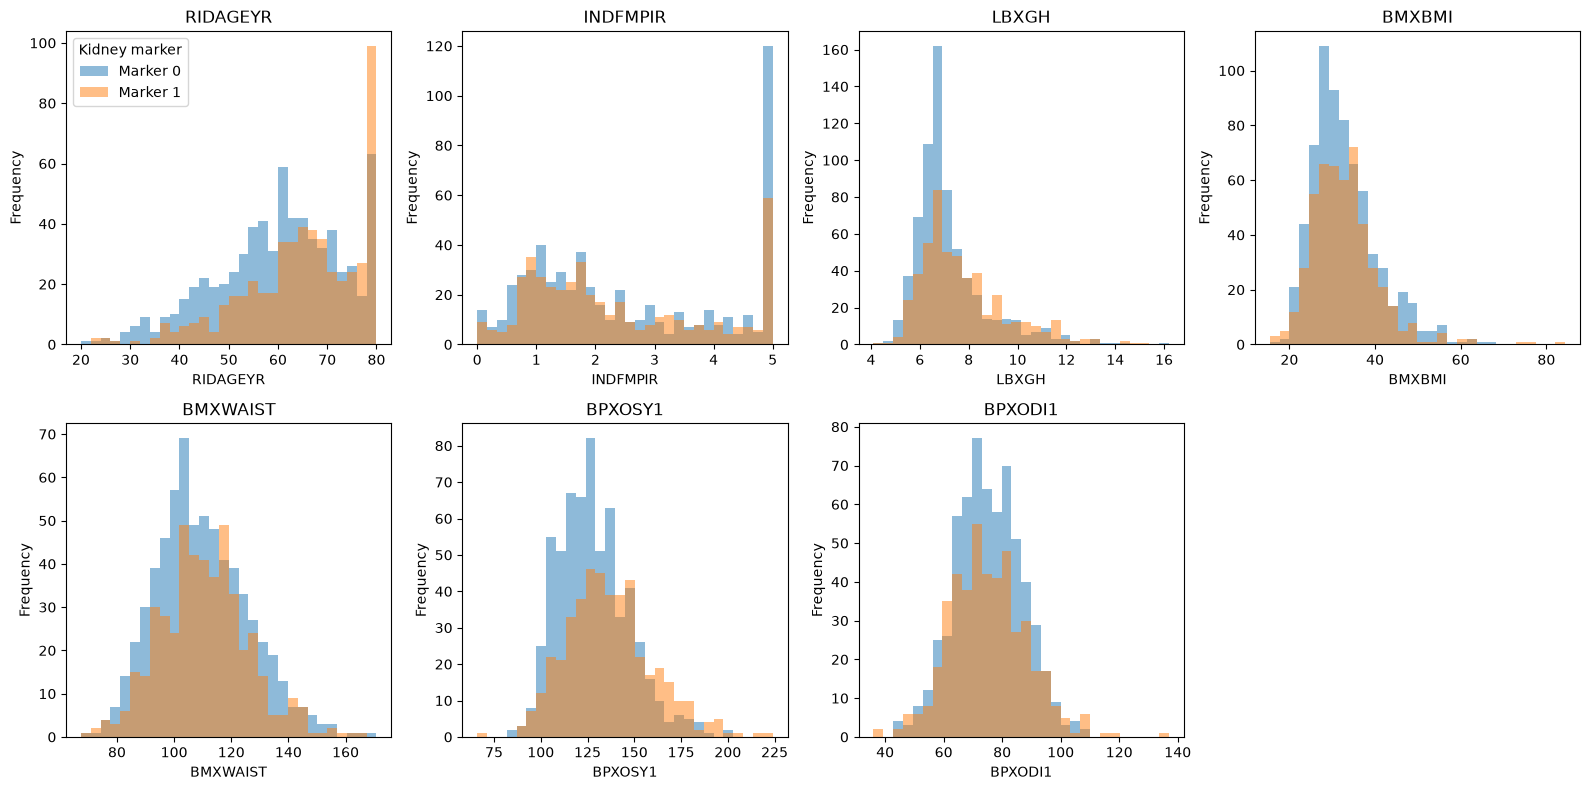

In [3]:
# Histograms of numerical predictors by kidney marker
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.ravel(), num):
    values = train[col].dropna()
    bins = np.histogram_bin_edges(values, bins=30)

    for label, group in train.groupby("kidney_marker"):
        ax.hist(
            group[col].dropna(),
            bins=bins,
            alpha=0.5,
            label=f"Marker {int(label)}"
        )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

axes.ravel()[0].legend(title="Kidney marker")
axes.ravel()[-1].set_visible(False)

plt.tight_layout()
plt.savefig(
    "../reports/figures/eda_numeric_by_outcome.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Exploratory Data Analysis – Key Findings

- **Age:** Kidney-marker prevalence increases across age groups, from 28% among participants aged 20–44 to 54% among those aged 70 and above.
- **HbA1c:** Higher HbA1c groups show higher kidney-marker prevalence. The rate increases from 35% in the below-6.5 group to 61% in the above-10 group.
- **Blood pressure:** Participants with kidney markers have a higher mean systolic blood pressure (137.34 mmHg) than those without markers (127.78 mmHg).
- **Body measurements:** BMI and waist circumference have a strong positive correlation (r = 0.89), indicating potential multicollinearity.
- **Blood pressure variables:** Systolic and diastolic blood pressure have a moderate positive correlation (r = 0.52).
- **Distribution:** HbA1c and BMI show positive skewness, suggesting that some participants have relatively high values.
- **Smoking and insulin:** Outcome prevalence varies across smoking and insulin-use categories. These are descriptive associations and should not be interpreted as causal relationships.

**Overall interpretation:** Age, HbA1c and systolic blood pressure show potentially meaningful differences across kidney-marker groups. BMI and waist circumference are strongly correlated and should be considered during feature selection and model development.

## 3. Outcome rate across clinically defined groups and collinearity

**Purpose:** (a) Describe how the proportion with a kidney marker varies across clinically meaningful strata. (b) Quantify linear correlation among continuous predictors to identify redundancy before modelling.

**Method:**
- Age bands: 20–44, 45–59, 60–69, 70+.
- HbA1c bands: < 6.5, 6.5–8, 8–10, > 10 %.
- Outcome rate (mean of the binary label) and group size for each stratum.
- Pearson correlation matrix of continuous predictors.

**Caution:** Strata are descriptive. Small groups (e.g. "unknown" smoking, n = 2) are not interpretable.

In [4]:
# 1. Age groups
train["age_group"] = pd.cut(
    train["RIDAGEYR"],
    bins=[19, 44, 59, 69, 80],
    labels=["20-44", "45-59", "60-69", "70+"]
)

# 2. HbA1c groups
train["a1c_group"] = pd.cut(
    train["LBXGH"],
    bins=[0, 6.5, 8, 10, 20],
    labels=["<6.5", "6.5-8", "8-10", ">10"]
)

# 3. Outcome rate across groups
for group in [
    "age_group",
    "a1c_group",
    "smoking",
    "insulin",
    "female"
]:
    print(f"\nOutcome rate by {group}:")
    print(
        train.groupby(group, observed=True)["kidney_marker"]
        .agg(["mean", "count"])
        .round(2)
    )

# 4. Correlation among numerical predictors
print("\nCorrelation matrix:")
print(train[num].corr().round(2))


Outcome rate by age_group:
           mean  count
age_group             
20-44      0.28    127
45-59      0.34    325
60-69      0.46    390
70+        0.54    362

Outcome rate by a1c_group:
           mean  count
a1c_group             
<6.5       0.35    354
6.5-8      0.39    535
8-10       0.55    196
>10        0.61    102

Outcome rate by smoking:
         mean  count
smoking             
current  0.43    185
former   0.49    379
never    0.39    638
unknown  0.50      2

Outcome rate by insulin:
         mean  count
insulin             
0.0      0.39    698
1.0      0.66    289

Outcome rate by female:
        mean  count
female             
0       0.47    642
1       0.39    562

Correlation matrix:
          RIDAGEYR  INDFMPIR  LBXGH  BMXBMI  BMXWAIST  BPXOSY1  BPXODI1
RIDAGEYR      1.00      0.04  -0.17   -0.21     -0.10     0.25    -0.29
INDFMPIR      0.04      1.00  -0.11   -0.05     -0.04    -0.07     0.02
LBXGH        -0.17     -0.11   1.00   -0.02     -0.01    -0.02  

##  Missing Value Analysis

**Purpose:** Identify missing values in candidate predictors before preprocessing.

**Method:** Calculate the number and percentage of missing observations in each predictor.

**Why it matters:** Missing values may require imputation. Imputation must be fitted using training data only to prevent data leakage.

In [22]:
# Missing value analysis for candidate predictors only

predictors = [
    "RIDAGEYR",
    "RIAGENDR",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BMXWAIST",
    "BPXOSY1",
    "BPXODI1",
    "smoking",
    "insulin",
    "female"
]

missing = pd.DataFrame({
    "missing_count": train[predictors].isna().sum(),
    "missing_percentage": (
        train[predictors].isna().mean() * 100
    ).round(2)
})

print(missing.sort_values(
    "missing_percentage",
    ascending=False
))

          missing_count  missing_percentage
insulin             217               18.02
INDFMPIR            163               13.54
BPXOSY1             126               10.47
BPXODI1             126               10.47
BMXWAIST             75                6.23
BMXBMI               26                2.16
LBXGH                17                1.41
RIAGENDR              0                0.00
RIDAGEYR              0                0.00
smoking               0                0.00
female                0                0.00


### Missing-value interpretation

The missingness analysis identified insulin use (18.02%), income-to-poverty ratio (13.54%), and blood pressure measurements (10.47%) as the predictors with the highest missingness.

BMI (2.16%) and HbA1c (1.41%) had relatively low missingness, while age, sex, and derived smoking status had no missing values.

Insulin missingness requires careful interpretation because questionnaire eligibility and skip patterns may contribute to missing responses. Missing insulin values are therefore not treated as non-use.

For subsequent modelling, numerical missing values will be imputed using training-set medians, with missingness indicators considered where appropriate. All imputation parameters will be learned from training data only and applied to the test data to prevent data leakage.

In [23]:
# Categorical predictor distributions

categorical = ["smoking", "female", "insulin"]

for col in categorical:
    print(f"\n{col} distribution:")
    print(train[col].value_counts(dropna=False))

    print(f"\n{col} by kidney marker:")
    print(
        pd.crosstab(
            train[col],
            train["kidney_marker"],
            normalize="index"
        ).round(2)
    )


smoking distribution:
smoking
never      638
former     379
current    185
unknown      2
Name: count, dtype: int64

smoking by kidney marker:
kidney_marker   0.0   1.0
smoking                  
current        0.57  0.43
former         0.51  0.49
never          0.61  0.39
unknown        0.50  0.50

female distribution:
female
0    642
1    562
Name: count, dtype: int64

female by kidney marker:
kidney_marker   0.0   1.0
female                   
0              0.53  0.47
1              0.61  0.39

insulin distribution:
insulin
0.0    698
1.0    289
NaN    217
Name: count, dtype: int64

insulin by kidney marker:
kidney_marker   0.0   1.0
insulin                  
0.0            0.61  0.39
1.0            0.34  0.66


Smoking
- Most participants were never smokers (638), followed by former smokers (379) and current smokers (185).
- The kidney-marker-positive proportion was 39% among never smokers, 49% among former smokers and 43% among current smokers.
- These are descriptive differences; they do not establish that smoking caused kidney-marker abnormalities.


Insulin
- Among participants with recorded insulin status, 66% of insulin users had a positive kidney marker, compared with 39% of non-users.
- Insulin status was missing for 18.02% of the training data, so this comparison uses only participants with recorded responses.
- Insulin use may reflect diabetes severity or treatment history; it should not be interpreted as a cause of kidney abnormalities.


Female
I can see the female distribution counts are 642 and 562, but the outcome percentages are missing from the pasted output. Please share the complete female by kidney marker table so we can finish this section accurately.

Correlation Analysis – Key Findings
- BMI and waist circumference showed a strong positive correlation (r = 0.89), indicating substantial overlap between these two measures.
- Systolic and diastolic blood pressure showed a moderate positive correlation (r = 0.52).
- Most other numerical predictor pairs showed weak correlations.
- These relationships should be considered during model interpretation. Correlation alone does not mean that a predictor must be removed.

Predictor Leakage Audit
The kidney-marker outcome was constructed using eGFR and UACR. Therefore, the variables used to calculate these measures must not be included as model predictors. This audit identifies variables that could introduce target leakage.

In [24]:
# Check variables that must not enter the model

leakage_columns = [
    "LBXSCR", "URXUMA", "URXUCR", "URDACT",
    "egfr", "kidney_marker"
]

print("Leakage-related columns present:")
print([col for col in leakage_columns if col in train.columns])

Leakage-related columns present:
['LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'egfr', 'kidney_marker']


In [25]:
# Final approved model predictors

predictors = [
    "RIDAGEYR",
    "female",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BMXWAIST",
    "BPXOSY1",
    "BPXODI1",
    "smoking",
    "insulin"
]

target = "kidney_marker"

print("Approved predictors:", predictors)
print("Target:", target)

print("\nPredictor columns available:")
print([col for col in predictors if col in train.columns])

print("\nMissing predictor columns:")
print([col for col in predictors if col not in train.columns])

Approved predictors: ['RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin']
Target: kidney_marker

Predictor columns available:
['RIDAGEYR', 'female', 'INDFMPIR', 'LBXGH', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'smoking', 'insulin']

Missing predictor columns:
[]


Leakage Audit – Interpretation

The variables LBXSCR, URXUMA, URXUCR, and URDACT were used to construct the kidney-marker outcome. The derived egfr variable also contributes to the outcome definition. Therefore, these variables must be excluded from model predictors to prevent target leakage. The target variable kidney_marker must be retained separately as the prediction label.

Final train/test validation

In [28]:
# ============================================================
# FINAL MODEL PREDICTOR SELECTION AND DATASET VALIDATION
# ============================================================

import pandas as pd
import numpy as np

# 1. Load existing datasets
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

# 2. Define approved primary model predictors
predictors = [
    "RIDAGEYR",     # Age
    "female",       # Sex
    "INDFMPIR",     # Income-to-poverty ratio
    "LBXGH",        # HbA1c
    "BMXBMI",       # Body mass index
    "BPXOSY1",      # Systolic blood pressure
    "BPXODI1",      # Diastolic blood pressure
    "smoking",      # Smoking status
    "insulin"       # Insulin use
]

# 3. Define target
target = "kidney_marker"

required_columns = predictors + [target]

print("=" * 55)
print("1. DATASET DIMENSIONS")
print("=" * 55)

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

# 4. Validate required columns
print("\n" + "=" * 55)
print("2. PREDICTOR VALIDATION")
print("=" * 55)

print("Number of approved predictors:", len(predictors))

print("Missing columns in training:",
      [c for c in required_columns if c not in train.columns])

print("Missing columns in testing:",
      [c for c in required_columns if c not in test.columns])

# 5. Check leakage-related variables
leakage_columns = [
    "LBXSCR",
    "URXUMA",
    "URXUCR",
    "URDACT",
    "egfr",
    "kidney_marker"
]

print("\n" + "=" * 55)
print("3. LEAKAGE AUDIT")
print("=" * 55)

print("Leakage-related columns present in training:")
print([c for c in leakage_columns if c in train.columns])

print("\nExcluded outcome-construction variables:")
print([c for c in leakage_columns if c != target])

# 6. Target distribution
print("\n" + "=" * 55)
print("4. TARGET DISTRIBUTION")
print("=" * 55)

print("\nTraining:")
print(train[target].value_counts())
print((train[target].value_counts(normalize=True) * 100).round(2))

print("\nTesting:")
print(test[target].value_counts())
print((test[target].value_counts(normalize=True) * 100).round(2))

# 7. Check missing target values
print("\n" + "=" * 55)
print("5. MISSING TARGET CHECK")
print("=" * 55)

print("Training missing targets:", train[target].isna().sum())
print("Testing missing targets:", test[target].isna().sum())

# 8. Check participant overlap
print("\n" + "=" * 55)
print("6. PARTICIPANT OVERLAP CHECK")
print("=" * 55)

overlap = set(train["SEQN"]).intersection(set(test["SEQN"]))

print("Number of overlapping participants:", len(overlap))

# 9. Final predictor dataset dimensions
X_train = train[predictors]
X_test = test[predictors]

y_train = train[target]
y_test = test[target]

print("\n" + "=" * 55)
print("7. FINAL MODEL INPUT DIMENSIONS")
print("=" * 55)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# 10. Final validation
print("\n" + "=" * 55)
print("8. FINAL VALIDATION")
print("=" * 55)

checks = {
    "All predictors available": all(c in train.columns and c in test.columns for c in predictors),
    "Target available": target in train.columns and target in test.columns,
    "No missing training targets": y_train.isna().sum() == 0,
    "No missing testing targets": y_test.isna().sum() == 0,
    "No participant overlap": len(overlap) == 0,
    "No outcome-construction variables in predictors": not any(
        c in predictors for c in leakage_columns
        if c != target
    )
}

for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

print("\nALL VALIDATION CHECKS PASSED:",
      all(checks.values()))

1. DATASET DIMENSIONS
Training dataset: (1204, 35)
Testing dataset: (302, 35)

2. PREDICTOR VALIDATION
Number of approved predictors: 9
Missing columns in training: []
Missing columns in testing: []

3. LEAKAGE AUDIT
Leakage-related columns present in training:
['LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'egfr', 'kidney_marker']

Excluded outcome-construction variables:
['LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'egfr']

4. TARGET DISTRIBUTION

Training:
kidney_marker
0.0    684
1.0    520
Name: count, dtype: int64
kidney_marker
0.0    56.81
1.0    43.19
Name: proportion, dtype: float64

Testing:
kidney_marker
0.0    171
1.0    131
Name: count, dtype: int64
kidney_marker
0.0    56.62
1.0    43.38
Name: proportion, dtype: float64

5. MISSING TARGET CHECK
Training missing targets: 0
Testing missing targets: 0

6. PARTICIPANT OVERLAP CHECK
Number of overlapping participants: 0

7. FINAL MODEL INPUT DIMENSIONS
X_train: (1204, 9)
X_test: (302, 9)
y_train: (1204,)
y_test: (302,)

8. FINAL VALIDAT

## 4. Findings and Interpretation

### 4.1 Data Quality

- The training dataset contains 1,204 participants.
- Age is top-coded at 80 years, and the income-to-poverty ratio is top-coded at 5.0. These are NHANES data conventions and should not automatically be treated as outliers.
- The maximum observed HbA1c was 16.2%, BMI was 84.4 kg/m², and systolic blood pressure was 224 mmHg.
- Extreme observations were retained for analysis rather than automatically removed. Their clinical plausibility should be considered during interpretation.

### 4.2 Distribution of Predictors

- HbA1c (skewness = 1.60) and BMI (skewness = 1.39) showed right-skewed distributions.
- Age was slightly left-skewed (skewness = −0.54).
- Income-to-poverty ratio, waist circumference, and blood pressure showed relatively mild skewness.
- The histograms showed considerable overlap between participants with and without kidney markers for several predictors. However, age, HbA1c, and systolic blood pressure showed some visible distributional differences between the two outcome groups.

### 4.3 Unadjusted Associations with Kidney Markers

- **Age:** The proportion of participants with kidney markers increased across age groups: 28%, 34%, 46%, and 54%. This association requires cautious interpretation because age is also a component of the eGFR calculation.
- **HbA1c:** Kidney-marker proportions increased across HbA1c categories: 35%, 39%, 55%, and 61%. The lowest HbA1c category includes participants identified through self-reported diabetes despite having HbA1c below 6.5%.
- **Blood Pressure:** Histograms suggested somewhat higher systolic blood pressure among participants with kidney markers, whereas diastolic blood pressure distributions showed substantial overlap.
- **Insulin:** The kidney-marker proportion was 66% among insulin users and 39% among non-users with recorded insulin status. This unadjusted association may reflect diabetes severity, treatment selection, or reverse causation.
- **Smoking:** Former smokers had the highest kidney-marker proportion (49%), followed by current smokers (43%) and never smokers (39%). Differences may be influenced by age and other confounding factors.
- **Sex:** The kidney-marker proportion was 47% among males and 39% among females.

These comparisons are descriptive and do not establish independent associations, statistical significance, or causality.

### 4.4 Correlation and Multicollinearity

- BMI and waist circumference showed a strong positive correlation (r = 0.89), indicating substantial overlap between these anthropometric measures.
- Systolic and diastolic blood pressure showed a moderate positive correlation (r = 0.52).
- Most other continuous predictor pairs showed relatively weak correlations.

The strong correlation between BMI and waist circumference was considered when selecting predictors for the primary model.

### 4.5 Decisions Based on EDA

| Decision | Rationale |
|---|---|
| Median imputation with missingness indicators, fitted within training folds only | Several numerical predictors contain missing observations. |
| Standard scaling for logistic regression | Places numerical predictors on comparable scales and supports model optimization. |
| Retain BMI and exclude waist circumference from the primary model | BMI and waist circumference are strongly correlated (r = 0.89). Waist circumference can be examined in a sensitivity model. |
| Derive smoking status using questionnaire skip patterns | Follow-up smoking responses are structurally missing for never-smokers. |
| Preserve missing insulin responses | Missing or not-asked responses must not be interpreted as insulin non-use. |
| Conduct sensitivity analysis without HbA1c | HbA1c contributes to the operational diabetes cohort definition. |
| Conduct sensitivity analysis without insulin | Insulin use may

In [29]:
import sys
sys.path.append("..")
import pandas as pd
from src.data_processing import load_raw_tables

tables = load_raw_tables("../data/raw")

In [30]:
keep = {
 "P_DEMO": ["SEQN", "RIDSTATR", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "RIDEXPRG",
           "INDFMPIR", "WTMECPRP", "SDMVPSU", "SDMVSTRA"],
"P_DIQ":["SEQN","DIQ010","DIQ050","DIQ070","DIQ160"],
 "P_GHB":["SEQN","LBXGH"],
 "P_BIOPRO":["SEQN","LBXSCR"],
 "P_ALB_CR":["SEQN","URXUMA","URXUCR","URDACT"],
 "P_BMX":["SEQN","BMXBMI","BMXWAIST"],
 "P_BPXO":["SEQN","BPXOSY1","BPXODI1"],
 "P_SMQ":["SEQN","SMQ020","SMQ040"]
}
merged = tables["P_DEMO"][keep["P_DEMO"]].copy()
for name in list(keep)[1:]:
    merged = merged.merge(tables[name][keep[name]], on="SEQN",
                          how="left", validate="one_to_one")
print(merged.shape)
assert len(merged) == 15560

(15560, 25)


In [31]:
# Identify adults aged 20 years or older
adults = merged[merged.RIDAGEYR >= 20].copy()

# Diabetes identification criteria
adults["dm_self"] = adults["DIQ010"] == 1
adults["dm_a1c"] = adults["LBXGH"] >= 6.5

# Primary diabetes definition:
# Self-reported diabetes OR HbA1c >= 6.5%
adults["diabetes"] = adults["dm_self"] | adults["dm_a1c"]

# Flag oral medication users reporting prediabetes
# without a diabetes diagnosis
adults["oral_med_prediabetes_only"] = (
    (adults["DIQ010"] == 2) &
    (adults["DIQ160"] == 1) &
    (adults["DIQ070"] == 1)
)

# Summary counts
print("Adults:", len(adults))
print("Self-reported diabetes:", adults["dm_self"].sum())
print("HbA1c >= 6.5%:", adults["dm_a1c"].sum())
print("Combined diabetes cohort:", adults["diabetes"].sum())

# Participants meeting each criterion
only_self = (
    adults["dm_self"] & ~adults["dm_a1c"]
).sum()

only_a1c = (
    adults["dm_a1c"] & ~adults["dm_self"]
).sum()

both = (
    adults["dm_self"] & adults["dm_a1c"]
).sum()

print("Only self-reported:", only_self)
print("Only HbA1c:", only_a1c)
print("Both criteria:", both)

# Medication-related descriptive information
pills_no_dx = adults[
    (adults["DIQ070"] == 1) &
    (adults["DIQ010"] != 1)
]

print(
    "Pills without diabetes diagnosis:", len(pills_no_dx),
    "| HbA1c >= 6.5%:", pills_no_dx["dm_a1c"].sum()
)

print(
    "Oral medication users reporting prediabetes "
    "without diabetes diagnosis:",
    adults["oral_med_prediabetes_only"].sum()
)

Adults: 9232
Self-reported diabetes: 1420
HbA1c >= 6.5%: 1171
Combined diabetes cohort: 1704
Only self-reported: 533
Only HbA1c: 284
Both criteria: 887
Pills without diabetes diagnosis: 108 | HbA1c >= 6.5%: 47
Oral medication users reporting prediabetes without diabetes diagnosis: 52


In [32]:
print(pd.crosstab(adults.DIQ010, adults.DIQ070, dropna=False))

DIQ070   1.0  2.0  9.0   NaN
DIQ010                      
1.0     1016  401    3     0
2.0       52  859    1  6633
3.0       56  205    1     0
9.0        0    2    0     3


In [33]:
# Diabetes cohort among adults
dm = adults[adults.diabetes].copy()

print("Diabetes cohort:", len(dm))

# Pregnancy status
print("\nPregnancy codes:")
print(dm.RIDEXPRG.value_counts(dropna=False))

# Adults without self-reported diabetes and with missing HbA1c
unknown_status = (
    (~adults.dm_self) &
    adults.LBXGH.isna()
)

print(
    "\nUnknown status (no self-reported diabetes, HbA1c missing):",
    unknown_status.sum()
)

# Missing HbA1c and examination weight
print("\nCohort HbA1c missing:", dm.LBXGH.isna().sum())

print(
    "Cohort WTMECPRP missing:",
    dm.WTMECPRP.isna().sum(),
    "| equal to 0:",
    (dm.WTMECPRP == 0).sum()
)

Diabetes cohort: 1704

Pregnancy codes:
RIDEXPRG
NaN    1607
2.0      84
3.0      10
1.0       3
Name: count, dtype: int64

Unknown status (no self-reported diabetes, HbA1c missing): 991

Cohort HbA1c missing: 160
Cohort WTMECPRP missing: 0 | equal to 0: 96


In [34]:
# Check whether RIDSTATR=2 matches WTMECPRP > 0
print(pd.crosstab(
    adults.RIDSTATR,
    adults.WTMECPRP > 0,
    dropna=False
))

# Restrict to examined adults
mec = adults[adults.RIDSTATR == 2].copy()

# Identify the updated diabetes cohort
dm_mec = mec[mec.diabetes].copy()

print("\nExamined adults:", len(mec))
print("Diabetes cohort:", len(dm_mec))

# Check missing HbA1c
print("Cohort HbA1c missing:", dm_mec.LBXGH.isna().sum())

# Check unknown diabetes status
unknown_status = (
    ~mec.dm_self &
    mec.LBXGH.isna()
)

print("Unknown status:", unknown_status.sum())

# Check pregnancy status
print("\nPregnancy status:")
print(dm_mec.RIDEXPRG.value_counts(dropna=False))

WTMECPRP  False  True 
RIDSTATR              
1.0         688      0
2.0           0   8544

Examined adults: 8544
Diabetes cohort: 1608
Cohort HbA1c missing: 64
Unknown status: 399

Pregnancy status:
RIDEXPRG
NaN    1517
2.0      84
3.0       4
1.0       3
Name: count, dtype: int64


cohort attrition table and outcome availability

In [35]:
# Final cohort: examined adults with diabetes,
# excluding pregnant and pregnancy-status-unascertained participants

cohort = dm_mec[
    ~dm_mec.RIDEXPRG.isin([1, 3])
].copy()

print("Final cohort:", len(cohort))

# Cohort attrition
flow = pd.DataFrame({
    "step": [
        "All participants",
        "Adults >=20",
        "Examined adults",
        "Diabetes (self-reported OR HbA1c >= 6.5%)",
        "Excluding pregnant/unascertained"
    ],
    "n": [
        len(merged),
        len(adults),
        len(mec),
        len(dm_mec),
        len(cohort)
    ]
})

display(flow)

# Kidney outcome availability
print("Creatinine missing:", cohort.LBXSCR.isna().sum())
print("UACR missing:", cohort.URDACT.isna().sum())
print(
    "Both missing:",
    (cohort.LBXSCR.isna() & cohort.URDACT.isna()).sum()
)
print("UACR >= 30:", (cohort.URDACT >= 30).sum())

Final cohort: 1601


,step,n
0,All participants,15560
1,Adults >=20,9232
2,Examined adults,8544
3,Diabetes (self-reported OR HbA1c >= 6.5%),1608
4,Excluding pregnant/unascertained,1601


Creatinine missing: 114
UACR missing: 56
Both missing: 15
UACR >= 30: 519


In [36]:
import numpy as np
from src.outcome_definition import egfr_ckdepi_2021, label_outcome

# Calculate kidney outcome using the updated cohort
labeled = label_outcome(cohort)

# Check kidney marker distribution
print("Kidney marker distribution:")
print(labeled.kidney_marker.value_counts(dropna=False))

# eGFR summary
print("\neGFR summary:")
print(labeled.egfr.describe())

# Kidney abnormality counts
print("\neGFR < 60:", (labeled.egfr < 60).sum())
print("UACR >= 30:", (labeled.URDACT >= 30).sum())

Kidney marker distribution:
kidney_marker
0.0    855
1.0    651
NaN     95
Name: count, dtype: int64

eGFR summary:
count    1487.000000
mean       83.507385
std        25.319714
min         2.958234
25%        67.338418
50%        87.786610
75%       102.486037
max       145.145698
Name: egfr, dtype: float64

eGFR < 60: 271
UACR >= 30: 519


In [37]:
from src.outcome_definition import egfr_ckdepi_2021, label_outcome

print(egfr_ckdepi_2021(np.array([1.0]), np.array([50]), np.array([False])))
print(egfr_ckdepi_2021(np.array([1.0]), np.array([50]), np.array([True])))

labeled = label_outcome(cohort)
print(labeled.kidney_marker.value_counts(dropna=False))
print(labeled.egfr.describe())
print("eGFR < 60:", (labeled.egfr < 60).sum())

[91.69147861]
[68.63349666]
kidney_marker
0.0    855
1.0    651
NaN     95
Name: count, dtype: int64
count    1487.000000
mean       83.507385
std        25.319714
min         2.958234
25%        67.338418
50%        87.786610
75%       102.486037
max       145.145698
Name: egfr, dtype: float64
eGFR < 60: 271


In [38]:
# Retain participants with an available kidney outcome
model_df = labeled[
    labeled.kidney_marker.notna()
].copy()

print("Modelling dataset shape:", model_df.shape)
print("\nKidney marker distribution:")
print(model_df.kidney_marker.value_counts())

# Sensitivity-analysis flag
model_df["pills_no_dx"] = (
    (model_df.DIQ070 == 1) &
    (model_df.DIQ010 != 1)
)

print(
    "\nPills without diabetes diagnosis:",
    model_df.pills_no_dx.sum()
)

# Save updated dataset
model_df.to_csv(
    "../data/interim/cohort_labeled.csv",
    index=False
)

Modelling dataset shape: (1506, 31)

Kidney marker distribution:
kidney_marker
0.0    855
1.0    651
Name: count, dtype: int64

Pills without diabetes diagnosis: 45


In [39]:
# Lowest eGFR rows: are they real?
print(labeled.sort_values("egfr")[["RIDAGEYR","RIAGENDR","LBXSCR","egfr","URDACT"]].head(8))
print("Max creatinine:", labeled.LBXSCR.max())

# Reasons for NaN labels
nan = labeled[labeled.kidney_marker.isna()]
print("Unlabeled:", len(nan))
print("Both missing:", (nan.egfr.isna() & nan.URDACT.isna()).sum())
print("Only creatinine missing (UACR normal):", (nan.egfr.isna() & nan.URDACT.notna()).sum())
print("Only UACR missing (eGFR normal):", (nan.egfr.notna() & nan.URDACT.isna()).sum())

       RIDAGEYR  RIAGENDR  LBXSCR      egfr   URDACT
11393      80.0       1.0   14.97  2.958234  1172.26
5749       72.0       2.0   10.96  3.383306      NaN
742        45.0       2.0   10.60  4.165567  3903.57
9136       66.0       1.0   10.78  4.785974  1555.26
15454      51.0       2.0    7.97  5.650477      NaN
13729      45.0       1.0    8.36  7.399229  5897.81
1359       66.0       1.0    7.43  7.480425      NaN
4568       80.0       1.0    6.75  7.693682  1561.18
Max creatinine: 14.97
Unlabeled: 95
Both missing: 15
Only creatinine missing (UACR normal): 63
Only UACR missing (eGFR normal): 17


In [40]:
# Keep only labelable people for modeling; keep the full labeled table for the report
model_df = labeled[labeled.kidney_marker.notna()].copy()
print(model_df.shape, model_df.kidney_marker.value_counts())

# Flag the sensitivity-analysis group: pills without a diabetes diagnosis
model_df["pills_no_dx"] = (model_df.DIQ070 == 1) & (model_df.DIQ010 != 1)
print("Pills-no-dx in modeling sample:", model_df.pills_no_dx.sum())

model_df.to_csv("../data/interim/cohort_labeled.csv", index=False)

(1506, 31) kidney_marker
0.0    855
1.0    651
Name: count, dtype: int64
Pills-no-dx in modeling sample: 45


In [41]:
pregnancy_check = adults[
    (adults.RIAGENDR == 2) &
    (adults.RIDAGEYR.between(20, 44))
]

print("Women aged 20–44:", len(pregnancy_check))

print("\nPregnancy status:")
print(pregnancy_check["RIDEXPRG"].value_counts(dropna=False))

print("\nMissing pregnancy status:")
print(pregnancy_check["RIDEXPRG"].isna().sum())

Women aged 20–44: 1874

Pregnancy status:
RIDEXPRG
2.0    1604
3.0     183
1.0      87
Name: count, dtype: int64

Missing pregnancy status:
0


In [42]:
pregnancy_check = adults[
    (adults.RIAGENDR == 2) &
    (adults.RIDAGEYR.between(20, 44))
]

print("Women aged 20–44:", len(pregnancy_check))

print("\nPregnancy status:")
print(pregnancy_check["RIDEXPRG"].value_counts(dropna=False))

print("\nMissing pregnancy status:")
print(pregnancy_check["RIDEXPRG"].isna().sum())

Women aged 20–44: 1874

Pregnancy status:
RIDEXPRG
2.0    1604
3.0     183
1.0      87
Name: count, dtype: int64

Missing pregnancy status:
0


In [43]:
print("Diabetes diagnosis vs prediabetes:")
print(pd.crosstab(
    adults["DIQ010"],
    adults["DIQ160"],
    dropna=False
))

print("\nOral medication users without diagnosed diabetes:")
print(
    adults.loc[
        (adults["DIQ010"] == 2) &
        (adults["DIQ070"] == 1),
        "DIQ160"
    ].value_counts(dropna=False)
)

Diabetes diagnosis vs prediabetes:
DIQ160  1.0   2.0  9.0   NaN
DIQ010                      
1.0       0     0    0  1420
2.0     912  6621   12     0
3.0       0     0    0   262
9.0       2     2    1     0

Oral medication users without diagnosed diabetes:
DIQ160
1.0    52
Name: count, dtype: int64


In [44]:
check = pd.read_csv("../data/interim/cohort_labeled.csv")

print("Saved dataset shape:", check.shape)
print("Missing target values:", check.kidney_marker.isna().sum())
print("Duplicate participant IDs:", check.SEQN.duplicated().sum())

Saved dataset shape: (1506, 32)
Missing target values: 0
Duplicate participant IDs: 0


In [45]:
print("In-memory columns:")
print(model_df.columns.tolist())

print("\nSaved CSV columns:")
print(check.columns.tolist())

print("\nUnexpected columns:")
print(set(check.columns) - set(model_df.columns))

In-memory columns:
['SEQN', 'RIDSTATR', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG', 'INDFMPIR', 'WTMECPRP', 'SDMVPSU', 'SDMVSTRA', 'DIQ010', 'DIQ050', 'DIQ070', 'DIQ160', 'LBXGH', 'LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'SMQ020', 'SMQ040', 'dm_self', 'dm_a1c', 'diabetes', 'oral_med_prediabetes_only', 'egfr', 'kidney_marker', 'pills_no_dx']

Saved CSV columns:
['SEQN', 'RIDSTATR', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG', 'INDFMPIR', 'WTMECPRP', 'SDMVPSU', 'SDMVSTRA', 'DIQ010', 'DIQ050', 'DIQ070', 'DIQ160', 'LBXGH', 'LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'SMQ020', 'SMQ040', 'dm_self', 'dm_a1c', 'diabetes', 'oral_med_prediabetes_only', 'egfr', 'kidney_marker', 'pills_no_dx']

Unexpected columns:
set()


In [46]:
# ==================================================
# FINAL MODEL-READY DATASET EXPORT
# ==================================================

import pandas as pd

# Load existing train and test datasets
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

# Approved primary predictors
predictors = [
    "RIDAGEYR",
    "female",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BPXOSY1",
    "BPXODI1",
    "smoking",
    "insulin"
]

target = "kidney_marker"

# Keep participant ID for traceability, not as a predictor
columns = ["SEQN"] + predictors + [target]

# Create clean modeling datasets
model_train = train[columns].copy()
model_test = test[columns].copy()

# Save files
model_train.to_csv(
    "../data/processed/model_train.csv",
    index=False
)

model_test.to_csv(
    "../data/processed/model_test.csv",
    index=False
)

# Verify
print("Model training dataset:", model_train.shape)
print("Model testing dataset:", model_test.shape)

print("\nTraining target distribution:")
print(model_train[target].value_counts())

print("\nTesting target distribution:")
print(model_test[target].value_counts())

print("\nMissing values:")
print("Training:\n", model_train.isna().sum())
print("\nTesting:\n", model_test.isna().sum())

Model training dataset: (1204, 11)
Model testing dataset: (302, 11)

Training target distribution:
kidney_marker
0.0    684
1.0    520
Name: count, dtype: int64

Testing target distribution:
kidney_marker
0.0    171
1.0    131
Name: count, dtype: int64

Missing values:
Training:
 SEQN               0
RIDAGEYR           0
female             0
INDFMPIR         163
LBXGH             17
BMXBMI            26
BPXOSY1          126
BPXODI1          126
smoking            0
insulin          217
kidney_marker      0
dtype: int64

Testing:
 SEQN              0
RIDAGEYR          0
female            0
INDFMPIR         41
LBXGH             6
BMXBMI            8
BPXOSY1          27
BPXODI1          27
smoking           0
insulin          54
kidney_marker     0
dtype: int64
